# Deep Learning

> [Kaggle Course - Intro to Deep Learning](https://www.kaggle.com/learn/intro-to-deep-learning)

**Lessons**
1. [A Single Neuron](https://www.kaggle.com/code/ryanholbrook/a-single-neuron)
    - Linear Unit or **Neuron**
    - Input Shape

2. [Deep Neural Networks](https://www.kaggle.com/code/ryanholbrook/deep-neural-networks)
    - Layers & Dense
    - Activation Functions: Rectified Linear Unit (ReLU), ELU, Sigmoid, etc.

3. [Stochastic Gradient Descent](https://www.kaggle.com/code/ryanholbrook/stochastic-gradient-descent)
    - Loss Functions: Tells what problem to solve (or) simply the objective.
        - Examples: Mean Squared Error (MSE), Mean Absolute Error (MAE), etc.
    - Optimizers: How to solve the problem. Example: Change the weights to minimize the loss.
        - MiniBatch
        - Epoch

    | Metric    | Values                                                            |
    |-----------|-------------------------------------------------------------------|
    | Dataset   | 1000 training rows / examples                                     |
    | MiniBatch | 100 - Each contains 10 rows / examples                            |
    | 1 Epoch   | 10 MiniBatches (i.e, one round trip of entrie datasets)           |
    | 10 Epoch  | 10 x 10 = 100 MiniBatches (i.e, 10 round trip of entrie datasets) |

4. [Overfitting and Underfitting]()

5. [Dropout and Batch Normalization]()

6. [Binary Classification]()

7. [Bonus: Detecting the Higgs Boson with TPUs]()

## Lesson 1 - A Single Neuron
- Learn about linear units, the building blocks of deep learning

#### Step 1 - Import necessary frameworks
- tensorflow, pandas

In [21]:
from tensorflow import keras
from tensorflow.keras import layers, callbacks
import pandas as pd

#### Step 2 - Load the data

In [2]:
red_wine_data = pd.read_csv("../resources/red-wine.csv")

#### Step 3 - Inspect Data

In [3]:
print(f"Shape: {red_wine_data.shape}")
print(f"Columns:\n{red_wine_data.columns}")
print(f"First 5 rows:\n{red_wine_data.head()}")

Shape: (1599, 12)
Columns:
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')
First 5 rows:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0 

In [4]:
red_wine_data.columns[0: -1]

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol'],
      dtype='str')

#### Step 4 - Define Model

| Metric | Value                                                                                                                                                                             |
|------|-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Inputs | 11 - ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides',  'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol'] |
| Output | quality                                                                                                                                                                           |
| Library | tensorflow.keras                                                                                                                                                                  |
| input_shape | (11, )                                                                                                                                                                            |

In [5]:
input_shape = (11, )
single_neuron_layer = layers.Dense(units = 1, input_shape = input_shape)
model = keras.Sequential([single_neuron_layer])
model.summary()

.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2026-10-10 11:23:56.987206: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5
2026-10-10 11:23:56.987222: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2026-10-10 11:23:56.987226: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 12.48 GB
I0000 00:00:1791591836.987235 16608260 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1791591836.987249 16608260 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical Pl

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12 (48.00 B)

 Trainable params: 12 (48.00 B)

 Non-trainable params: 0 (0.00 B)

#### Step 5 - Inspect Model

In [6]:
weights, bias = model.weights
print(f"Input Shape : {model.input_shape}, Output Shape : {model.output_shape}")
print(f"Weights: {weights}")
print(f"Bias: {bias}")

Input Shape : (None, 11), Output Shape : (None, 1)
Weights: <Variable path=sequential/dense/kernel, shape=(11, 1), dtype=float32, value=[[ 0.66086143]
 [ 0.00425243]
 [-0.37132907]
 [-0.41736406]
 [ 0.4584728 ]
 [ 0.47501892]
 [ 0.06131762]
 [-0.6152956 ]
 [ 0.01793265]
 [ 0.65991396]
 [ 0.17550284]]>
Bias: <Variable path=sequential/dense/bias, shape=(1,), dtype=float32, value=[0.]>


## Lesson 2 - Deep Neural Networks

#### Step 1 - Multi Layer Neural Network

In [7]:
concrete_data = pd.read_csv('../resources/concrete.csv')
concrete_data.head()

,Cement,BlastFurnaceSlag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,CompressiveStrength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


#### Step 2 - Define the Model

| Metric                       | Value                                                                                              |
|------------------------------|----------------------------------------------------------------------------------------------------|
| Inputs                       | 8 - Cement, BlastFurnaceSlag, FlyAsh, Water, Superplasticizer, CoarseAggregate, FineAggregate, Age |
| Output                       | CompressiveStrength                                                                                |
| Hidden Layers & Neurons/Unit | 3 & 512 units                                                                                      |
| Hidden Layer Activation      | ReLU (Rectified Linear Unit)                                                                       |
| Output Layer                 | 1                                                                                                  |

In [8]:
input_columns = concrete_data.columns[0: -1]
output_column = concrete_data.columns[-1]

print(f"Input: {input_columns} | Total : {len(input_columns)}\nOutput: {output_column}")

Input: Index(['Cement', 'BlastFurnaceSlag', 'FlyAsh', 'Water', 'Superplasticizer',
       'CoarseAggregate', 'FineAggregate', 'Age'],
      dtype='str') | Total : 8
Output: CompressiveStrength


In [9]:
concrete_model = keras.Sequential(
    [
        # 3 Hidden Layers with 512 neurons each
        layers.Dense(units = 512, activation = 'relu', input_shape = (8, )),
        layers.Dense(units = 512, activation = 'relu'),
        layers.Dense(units = 512, activation = 'relu'),

        # Output Layer
        layers.Dense(1),
    ]
)

.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


#### Step 3 - Explore the Model

In [10]:
weights = concrete_model.get_weights()
for w in weights:
    print(w.shape)

(8, 512)
(512,)
(512, 512)
(512,)
(512, 512)
(512,)
(512, 1)
(1,)


#### Step 4 - Neural Network Architecture For a Single Row

![image](../resources/images/lesson_2_neural_network_arch.png)

## Lesson 3 - Stochastic Gradient Descent

#### Import the necessary frameworks
    - numpy, pandas, sklearn

In [11]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_selector, make_column_transformer
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

#### Step 1 - Load the fuel data

In [12]:
fuel_data = pd.read_csv("../resources/fuel.csv")
fuel_data.head()

,EngDispl,NumCyl,Transmission,FE,AirAspirationMethod,NumGears,TransLockup,TransCreeperGear,DriveDesc,IntakeValvePerCyl,ExhaustValvesPerCyl,CarlineClassDesc,VarValveTiming,VarValveLift
0,4.7,8,AM6,28.0198,NaturallyAspirated,6,1,0,TwoWheelDriveRear,2,2,2Seaters,1,0
1,4.7,8,M6,25.6094,NaturallyAspirated,6,1,0,TwoWheelDriveRear,2,2,2Seaters,1,0
2,4.2,8,M6,26.8000,NaturallyAspirated,6,1,0,AllWheelDrive,2,2,2Seaters,1,0
3,4.2,8,AM6,25.0451,NaturallyAspirated,6,1,0,AllWheelDrive,2,2,2Seaters,1,0
4,5.2,10,AM6,24.8000,NaturallyAspirated,6,0,0,AllWheelDrive,2,2,2Seaters,1,0


#### Step 2 - Understand the data

1. Target - Derive Fuel Economy 'FE' as output
2. Features - Remaining columns excluding the target 'FE'

In [13]:
# make a deep copy of the original fuel data
X = fuel_data.copy()

# target column
y = X.pop('FE')

print(y.head())
print(X.head())

0    28.0198
1    25.6094
2    26.8000
3    25.0451
4    24.8000
Name: FE, dtype: float64
   EngDispl  NumCyl Transmission AirAspirationMethod  NumGears  TransLockup  \
0       4.7       8          AM6  NaturallyAspirated         6            1   
1       4.7       8           M6  NaturallyAspirated         6            1   
2       4.2       8           M6  NaturallyAspirated         6            1   
3       4.2       8          AM6  NaturallyAspirated         6            1   
4       5.2      10          AM6  NaturallyAspirated         6            0   

   TransCreeperGear          DriveDesc  IntakeValvePerCyl  \
0                 0  TwoWheelDriveRear                  2   
1                 0  TwoWheelDriveRear                  2   
2                 0      AllWheelDrive                  2   
3                 0      AllWheelDrive                  2   
4                 0      AllWheelDrive                  2   

   ExhaustValvesPerCyl CarlineClassDesc  VarValveTiming  VarValveLif

In [14]:
preprocessor = make_column_transformer(
    # SS normalize the numerical features / columns
    (StandardScaler(), make_column_selector(dtype_include = np.number)),

    # OHE converts categorical features to numerical features, and bloats up the columns
    (OneHotEncoder(sparse_output=False), make_column_selector(dtype_include = object))
)

X = preprocessor.fit_transform(X)
y = np.log(y)


In [15]:
print(X.shape)
print(y.shape)
print((X.shape[1], ))

(1107, 50)
(1107,)
(50,)


In [16]:
pp_features = preprocessor.get_feature_names_out()
for name in pp_features:
    print(name)

standardscaler__EngDispl
standardscaler__NumCyl
standardscaler__NumGears
standardscaler__TransLockup
standardscaler__TransCreeperGear
standardscaler__IntakeValvePerCyl
standardscaler__ExhaustValvesPerCyl
standardscaler__VarValveTiming
standardscaler__VarValveLift
onehotencoder__Transmission_A4
onehotencoder__Transmission_A5
onehotencoder__Transmission_A6
onehotencoder__Transmission_A7
onehotencoder__Transmission_AM6
onehotencoder__Transmission_AM7
onehotencoder__Transmission_AV
onehotencoder__Transmission_AVS6
onehotencoder__Transmission_M5
onehotencoder__Transmission_M6
onehotencoder__Transmission_Other
onehotencoder__Transmission_S4
onehotencoder__Transmission_S5
onehotencoder__Transmission_S6
onehotencoder__Transmission_S7
onehotencoder__Transmission_S8
onehotencoder__AirAspirationMethod_NaturallyAspirated
onehotencoder__AirAspirationMethod_Supercharged
onehotencoder__AirAspirationMethod_Turbocharged
onehotencoder__DriveDesc_AllWheelDrive
onehotencoder__DriveDesc_FourWheelDrive
oneh

#### Step 3 - Define the Model

In [17]:
fuel_model = keras.Sequential(
    [
        layers.Input(shape = (X.shape[1], )),
        layers.Dense(units = 128, activation = 'relu'),
        layers.Dense(units = 128, activation = 'relu'),
        layers.Dense(units = 64, activation = 'relu'),
        layers.Dense(units = 1)
    ]
)

#### Step 5 - Add Loss and Optimizer

In [18]:
fuel_model.compile(optimizer="Adam", loss="mae")

#### Step 6 - Train the Model

In [19]:
fuel_training_history = fuel_model.fit(x=X, y=y, batch_size=128, epochs=200)

Epoch 1/200


2026-10-10 11:23:57.575916: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 2.5021
Epoch 2/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.7581
Epoch 3/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.5228
Epoch 4/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3507
Epoch 5/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2324
Epoch 6/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1568
Epoch 7/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1195
Epoch 8/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1002
Epoch 9/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0906
Epoch 10/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0927
Epoch 11/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0803
Epoch 12/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0795
Epoch 13/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0840
Epoch 14/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0817
Epoch 15/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1110
Epoch 16/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/

#### Step 7 - Inspect Loss from training

<Axes: >

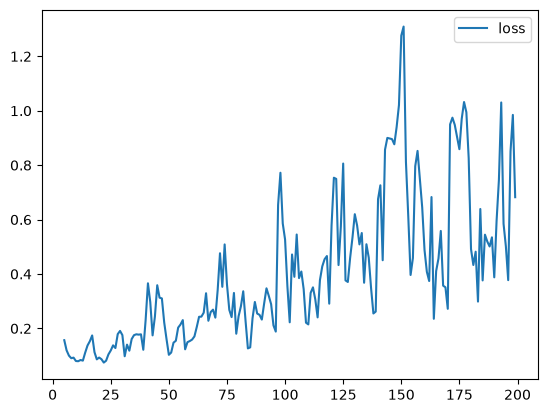

In [20]:
fuel_training_history_df = pd.DataFrame(fuel_training_history.history)
fuel_training_history_df.loc[5:, ['loss']].plot()

## Lesson 4 - Overfitting and Underfitting

In [22]:
from IPython.display import display

df_red_wine_train = red_wine_data.sample(frac=0.7, random_state=0)
df_red_wine_valid = red_wine_data.drop(df_red_wine_train.index)
display(df_red_wine_train.head())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1109,10.8,0.470,0.43,2.10,0.171,27.0,66.0,0.99820,3.17,0.76,10.8,6
1032,8.1,0.820,0.00,4.10,0.095,5.0,14.0,0.99854,3.36,0.53,9.6,5
1002,9.1,0.290,0.33,2.05,0.063,13.0,27.0,0.99516,3.26,0.84,11.7,7
487,10.2,0.645,0.36,1.80,0.053,5.0,14.0,0.99820,3.17,0.42,10.0,6
979,12.2,0.450,0.49,1.40,0.075,3.0,6.0,0.99690,3.13,0.63,10.4,5


In [23]:
max_red_wine = df_red_wine_train.max(axis=0)
min_red_wine = df_red_wine_train.min(axis=0)
df_red_wine_train = (df_red_wine_train - min_red_wine) / (max_red_wine - min_red_wine)
df_red_wine_valid = (df_red_wine_valid - min_red_wine) / (max_red_wine - min_red_wine)

X_rw_train = df_red_wine_train.drop('quality', axis=1)
X_rw_valid = df_red_wine_valid.drop('quality', axis=1)

y_rw_train = df_red_wine_train['quality']
y_rw_valid = df_red_wine_valid['quality']

#### Step 1 - Add Early Stopping callback

In [24]:
early_stopping = callbacks.EarlyStopping(
    min_delta=0.001,
    patience=20,
    restore_best_weights=True
)

red_wine_model = keras.Sequential(
    [
        layers.Input(shape=(11, )),
        layers.Dense(units=512, activation='relu'),
        layers.Dense(units=512, activation='relu'),
        layers.Dense(units=512, activation='relu'),
        layers.Dense(units=1)
    ]
)

red_wine_model.compile(
    optimizer="Adam",
    loss="mae"
)

<Axes: >

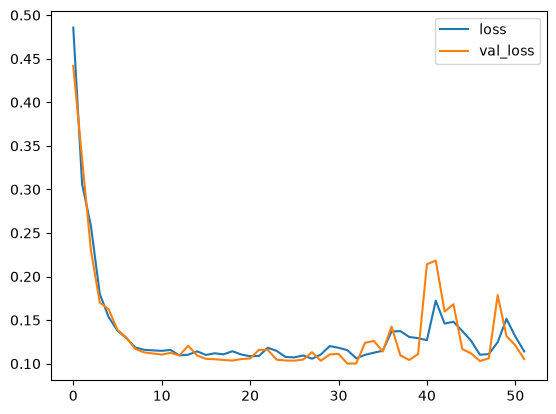

In [25]:
red_wine_history = red_wine_model.fit(
    X_rw_train,
    y_rw_train,
    batch_size=256,
    epochs=500,
    validation_data=(X_rw_valid, y_rw_valid),
    callbacks=[early_stopping],
    verbose=0
)

red_wine_history_df = pd.DataFrame(red_wine_history.history)
red_wine_history_df.loc[:, ['loss', 'val_loss']].plot()

In [28]:
print("Minimum validation loss: {}".format(red_wine_history_df['val_loss'].min()))

Minimum validation loss: 0.10005033016204834


## Lesson 5 - Dropout and Batch Normalization

In [29]:
red_wine_model = keras.Sequential(
    [
        layers.Input(shape=(11, )),
        layers.Dropout(0.3),
        layers.BatchNormalization(),
        layers.Dense(units=1024, activation='relu'),
        layers.Dropout(0.3),
        layers.BatchNormalization(),
        layers.Dense(units=1024, activation='relu'),
        layers.Dropout(0.3),
        layers.BatchNormalization(),
        layers.Dense(units=1),
    ]
)

red_wine_model.compile(
    optimizer="Adam",
    loss="mae"
)

<Axes: >

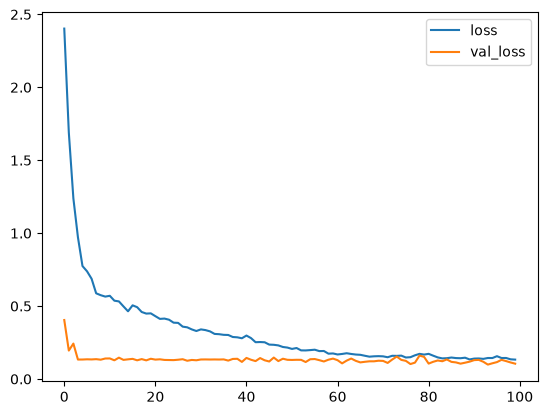

In [30]:
red_wine_history = red_wine_model.fit(
    X_rw_train,
    y_rw_train,
    validation_data=(X_rw_valid, y_rw_valid),
    batch_size=256,
    epochs=100,
    verbose=0
)

red_wine_history_df = pd.DataFrame(red_wine_history.history)
red_wine_history_df.loc[:, ['loss', 'val_loss']].plot()